# Pretrained denoising autoencoder for recorded BSG windows

This notebook is a self-contained inference tutorial. It loads the pretrained ONNX model,
defines all preprocessing and inference functions, reads a bundled pool of 1000 recorded
BSG windows, displays randomly selected examples, identifies spike-like windows, and
explores repeated denoising passes.

There is no model training, checkpoint creation, external helper script, or GPU
requirement. The model contract is fixed: one 100 Hz window containing exactly 1000
samples. Its output remains in standardized amplitude units.


## Denoising autoencoder overview

A conventional autoencoder compresses an input $x$ into a latent representation $z$ and
reconstructs the same $x$. A denoising autoencoder instead receives a corrupted input
$\tilde{x}$ while retaining the clean signal $x$ as the training target:

$$
\tilde{x}\sim q(\tilde{x}\mid x),\qquad
z=f_\theta(\tilde{x}),\qquad
\hat{x}=g_\phi(z),\qquad
\min_{\theta,\phi}\;\mathbb{E}\left[\mathcal{L}(\hat{x},x)\right].
$$

- The **encoder** learns a representation that should be less sensitive to corruption.
- The **decoder** reconstructs a signal from that representation.
- Common objectives include MSE, MAE, frequency-domain losses, and derivative or
  morphology losses.
- The training corruption distribution should resemble deployment artifacts; otherwise,
  domain shift can reduce performance.
- A denoised output is a model estimate rather than a new observation. Severe artifacts
  or missing intervals can be smoothed or reconstructed incorrectly.

The next two cells separate the conceptual training process from the exported inference
path used in this notebook. The original training architecture and loss are not inferred
from the ONNX file.


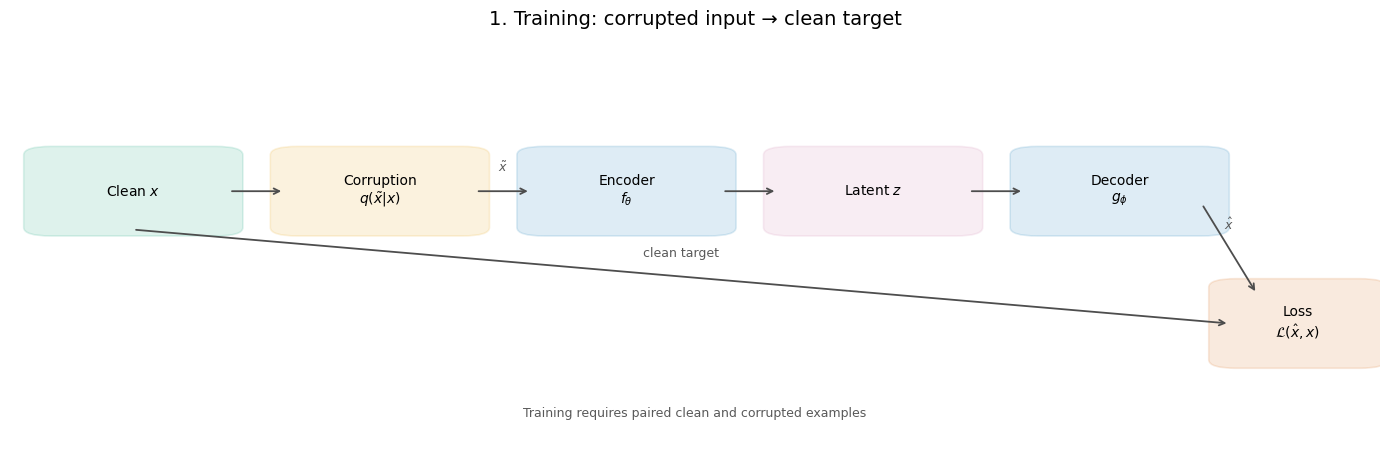

In [7]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

def draw_box(axis, center, text, color, width=0.145, height=0.18):
    x, y = center
    box = FancyBboxPatch(
        (x - width / 2, y - height / 2), width, height,
        boxstyle="round,pad=0.015,rounding_size=0.02",
        linewidth=1.2, edgecolor=color, facecolor=color, alpha=0.13,
    )
    axis.add_patch(box)
    axis.text(x, y, text, ha="center", va="center", fontsize=10)

def connect(axis, start, end, label=None):
    axis.annotate(
        "", xy=end, xytext=start,
        arrowprops=dict(arrowstyle="->", linewidth=1.3, color="0.3"),
    )
    if label:
        axis.text(
            (start[0] + end[0]) / 2, (start[1] + end[1]) / 2 + 0.055,
            label, ha="center", va="center", fontsize=9, color="0.35",
        )

fig, ax = plt.subplots(figsize=(14, 4.8))
ax.set_title("1. Training: corrupted input → clean target", fontsize=14)
train_nodes = [
    ((0.09, 0.63), "Clean $x$", "#009E73"),
    ((0.27, 0.63), "Corruption\n$q(\\tilde{x}|x)$", "#E69F00"),
    ((0.45, 0.63), "Encoder\n$f_\\theta$", "#0072B2"),
    ((0.63, 0.63), "Latent $z$", "#CC79A7"),
    ((0.81, 0.63), "Decoder\n$g_\\phi$", "#0072B2"),
    ((0.94, 0.32), "Loss\n$\\mathcal{L}(\\hat{x},x)$", "#D55E00"),
]
for center, text, color in train_nodes:
    draw_box(ax, center, text, color, width=0.13 if center[0] != 0.94 else 0.10)
connect(ax, (0.16, 0.63), (0.20, 0.63))
connect(ax, (0.34, 0.63), (0.38, 0.63), "$\\tilde{x}$")
connect(ax, (0.52, 0.63), (0.56, 0.63))
connect(ax, (0.70, 0.63), (0.74, 0.63))
connect(ax, (0.87, 0.60), (0.91, 0.39), "$\\hat{x}$")
connect(ax, (0.09, 0.54), (0.89, 0.32), "clean target")
ax.text(
    0.5, 0.10, "Training requires paired clean and corrupted examples",
    ha="center", fontsize=9, color="0.35",
)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.axis("off")
fig.tight_layout()
plt.show()


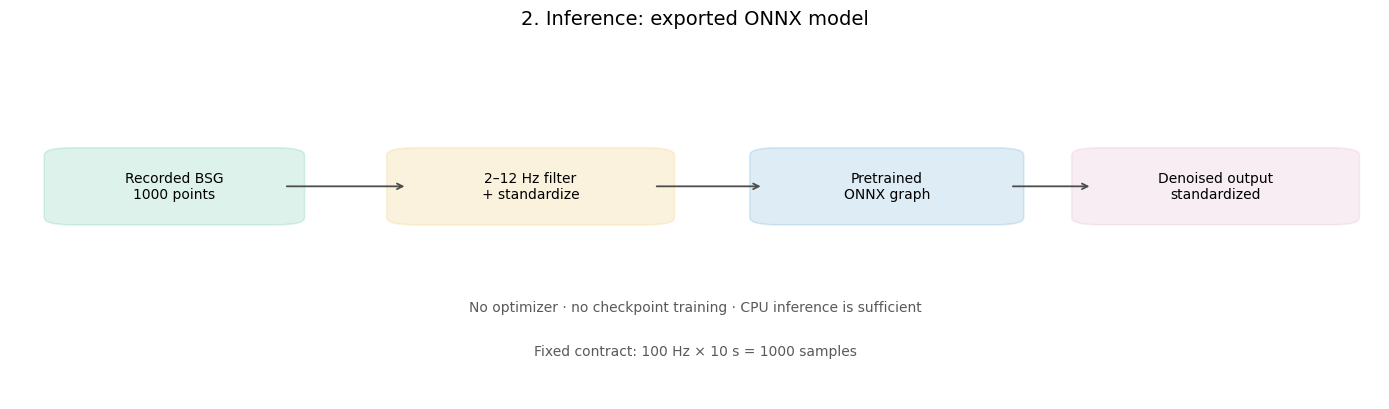

In [8]:
fig, ax = plt.subplots(figsize=(14, 4.2))
ax.set_title("2. Inference: exported ONNX model", fontsize=14)

inference_nodes = [
    ((0.12, 0.58), "Recorded BSG\n1000 points", "#009E73", 0.16),
    ((0.38, 0.58), "2–12 Hz filter\n+ standardize", "#E69F00", 0.18),
    ((0.64, 0.58), "Pretrained\nONNX graph", "#0072B2", 0.17),
    ((0.88, 0.58), "Denoised output\nstandardized", "#CC79A7", 0.18),
]
for center, text, color, width in inference_nodes:
    draw_box(ax, center, text, color, width=width)
connect(ax, (0.20, 0.58), (0.29, 0.58))
connect(ax, (0.47, 0.58), (0.55, 0.58))
connect(ax, (0.73, 0.58), (0.79, 0.58))
ax.text(
    0.5, 0.24, "No optimizer · no checkpoint training · CPU inference is sufficient",
    ha="center", fontsize=10, color="0.35",
)
ax.text(
    0.5, 0.12, "Fixed contract: 100 Hz × 10 s = 1000 samples",
    ha="center", fontsize=10, color="0.35",
)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.axis("off")
fig.tight_layout()
plt.show()


## 1. Load the model

Start Jupyter from either the repository root or `tutorials/extension`. Install the
repository requirements first. The minimal dependencies are `numpy`, `scipy`,
`matplotlib`, and `onnxruntime`.


In [9]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import onnxruntime as ort
from scipy.signal import butter, filtfilt

FS = 100
WINDOW_SAMPLES = 1000

candidates = [
    Path.cwd() / "tutorials" / "extension",
    Path.cwd(),
    Path.cwd() / "extension",
]
EXTENSION_DIR = next(
    (path.resolve() for path in candidates if (path / "denoise.onnx").exists()),
    None,
)
if EXTENSION_DIR is None:
    raise FileNotFoundError(
        "Could not find tutorials/extension/denoise.onnx. "
        "Start Jupyter from the repository checkout."
    )

class DenoiseModel:
    def __init__(self, model_path):
        self.model_path = Path(model_path)
        self.session = ort.InferenceSession(
            str(self.model_path), providers=["CPUExecutionProvider"],
        )
        self.input_name = self.session.get_inputs()[0].name

    @staticmethod
    def preprocess(signal, fs=FS):
        signal = np.asarray(signal, dtype=np.float64)
        if fs != FS:
            raise ValueError(f"Expected {FS} Hz, got {fs} Hz")
        if signal.shape != (WINDOW_SAMPLES,):
            raise ValueError(f"Expected ({WINDOW_SAMPLES},), got {signal.shape}")
        if not np.isfinite(signal).all():
            raise ValueError("The input must contain only finite values")
        b, a = butter(3, [2 / (fs * 0.5), 12 / (fs * 0.5)], "bandpass")
        filtered = filtfilt(b, a, signal)
        scale = filtered.std()
        normalized = filtered - filtered.mean()
        if scale > 0:
            normalized /= scale
        return normalized.astype(np.float32)

    def predict(self, signal, fs=FS):
        model_input = self.preprocess(signal, fs=fs)[None, :]
        output = self.session.run(None, {self.input_name: model_input})[0]
        return np.asarray(output[0], dtype=np.float32)

model = DenoiseModel(EXTENSION_DIR / "denoise.onnx")
session_input = model.session.get_inputs()[0]
session_output = model.session.get_outputs()[0]
print(f"Model: {model.model_path}")
print(f"Input : {session_input.name}, shape={session_input.shape}, type={session_input.type}")
print(f"Output: {session_output.name}, shape={session_output.shape}, type={session_output.type}")
assert session_input.shape == [1, WINDOW_SAMPLES]
assert session_output.shape == [1, WINDOW_SAMPLES]


Model: /Users/jc67805/Documents/Phd/SensorAI/tutorials/extension/denoise.onnx
Input : input, shape=[1, 1000], type=tensor(float)
Output: output, shape=[1, 1000], type=tensor(float)


## 2. Load the recorded signal pool

The bundled anonymized pool contains 1000 recorded BSG windows. Every row contains exactly
1000 finite samples. Source identifiers and timestamps are not included. Six display rows
were selected reproducibly with a fixed random seed.


In [10]:
sample_path = EXTENSION_DIR / "random_1000_signals.npz"
with np.load(sample_path, allow_pickle=False) as saved:
    signals = saved["signals"].copy()
    display_indices = saved["display_indices"].copy()
    sampling_seed = int(saved["sampling_seed"])

if signals.shape != (1000, WINDOW_SAMPLES):
    raise ValueError(f"Expected a (1000, 1000) signal pool, got {signals.shape}")
if not np.isfinite(signals).all():
    raise ValueError("The signal pool contains NaN or Inf values")
if not np.all((0 <= display_indices) & (display_indices < len(signals))):
    raise ValueError("The stored display indices are invalid")

print("signals:", signals.shape, signals.dtype)
print("sampling seed:", sampling_seed)
print("random display rows:", display_indices.tolist())


signals: (1000, 1000) float32
sampling seed: 20261106
random display rows: [146, 164, 202, 411, 686, 782]


## 3. Random examples

The gray trace is the input after the same 2–12 Hz filter and standardization used by the
model. The blue trace is the model output. This shared scale makes the overlay meaningful.

These recorded windows have no paired clean target. Input/output correlation describes
how much the output resembles the preprocessed input; it is not an accuracy or denoising
quality score.


row 146: raw range=(-1036755, 972716), input/output correlation=0.994
row 164: raw range=(-697423, 1123994), input/output correlation=0.963
row 202: raw range=(15393, 16078), input/output correlation=0.949
row 411: raw range=(9015, 25399), input/output correlation=0.927
row 686: raw range=(-2925976, 1899515), input/output correlation=0.927
row 782: raw range=(-4255252, 5272539), input/output correlation=0.830


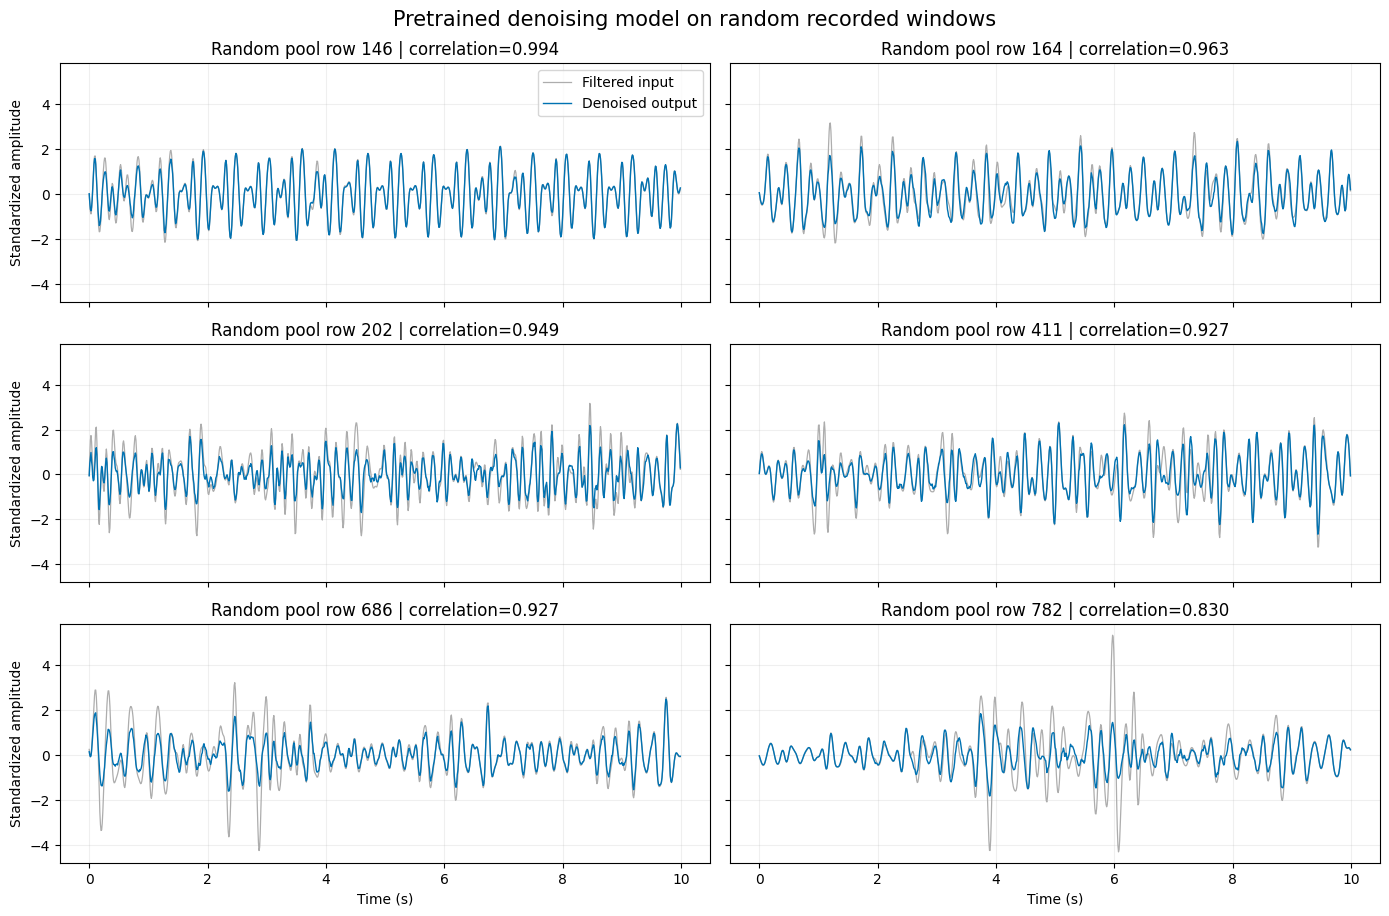

In [11]:
def run_examples(model, signals, indices):
    results = []
    for pool_index in indices:
        raw = signals[int(pool_index)]
        filtered_input = model.preprocess(raw)
        denoised = model.predict(raw)
        results.append(
            {
                "pool_index": int(pool_index),
                "raw": raw,
                "filtered_input": filtered_input,
                "denoised": denoised,
                "correlation": float(np.corrcoef(filtered_input, denoised)[0, 1]),
            }
        )
    return results

def plot_examples(results):
    time = np.arange(WINDOW_SAMPLES) / FS
    rows = int(np.ceil(len(results) / 2))
    fig, axes = plt.subplots(rows, 2, figsize=(14, 3.1 * rows), sharex=True, sharey=True)
    axes = np.atleast_1d(axes).reshape(-1)
    for axis, result in zip(axes, results):
        axis.plot(
            time, result["filtered_input"], color="0.68", linewidth=0.9,
            label="Filtered input",
        )
        axis.plot(
            time, result["denoised"], color="#0072B2", linewidth=1.0,
            label="Denoised output",
        )
        axis.set_title(
            f"Random pool row {result['pool_index']} | "
            f"correlation={result['correlation']:.3f}"
        )
        axis.grid(alpha=0.2)
    for axis in axes[len(results):]:
        axis.set_visible(False)
    axes[0].legend(loc="upper right")
    for axis in axes[-2:]:
        if axis.get_visible():
            axis.set_xlabel("Time (s)")
    for axis in axes[::2]:
        if axis.get_visible():
            axis.set_ylabel("Standardized amplitude")
    fig.suptitle("Pretrained denoising model on random recorded windows", fontsize=15)
    fig.tight_layout()
    return fig

example_results = run_examples(model, signals, display_indices)
for result in example_results:
    raw = result["raw"]
    print(
        f"row {result['pool_index']:>3}: raw range=({raw.min():.0f}, {raw.max():.0f}), "
        f"input/output correlation={result['correlation']:.3f}"
    )
plot_examples(example_results)
plt.show()


## 4. Injected spikes and repeated denoising

To create a controlled demonstration, one to three impulse spikes are added to each of
four recorded windows. Spike counts, positions, signs, and amplitudes are generated with
a fixed random seed. Amplitudes are sampled between 100 and 200 times the standard
deviation of the original window.

The original recorded window is shown as a reference, but it is not assumed to be a clean
ground-truth signal. The spiked window is passed through the model four times. Repeated
inference is experimental: later passes can suppress real morphology, shift peaks, or
introduce ringing.


Rows used for spike injection: [146, 164, 202, 411]
row 146: spike positions=[50, 816, 827]
row 164: spike positions=[292, 530, 744]
row 202: spike positions=[573]
row 411: spike positions=[805]


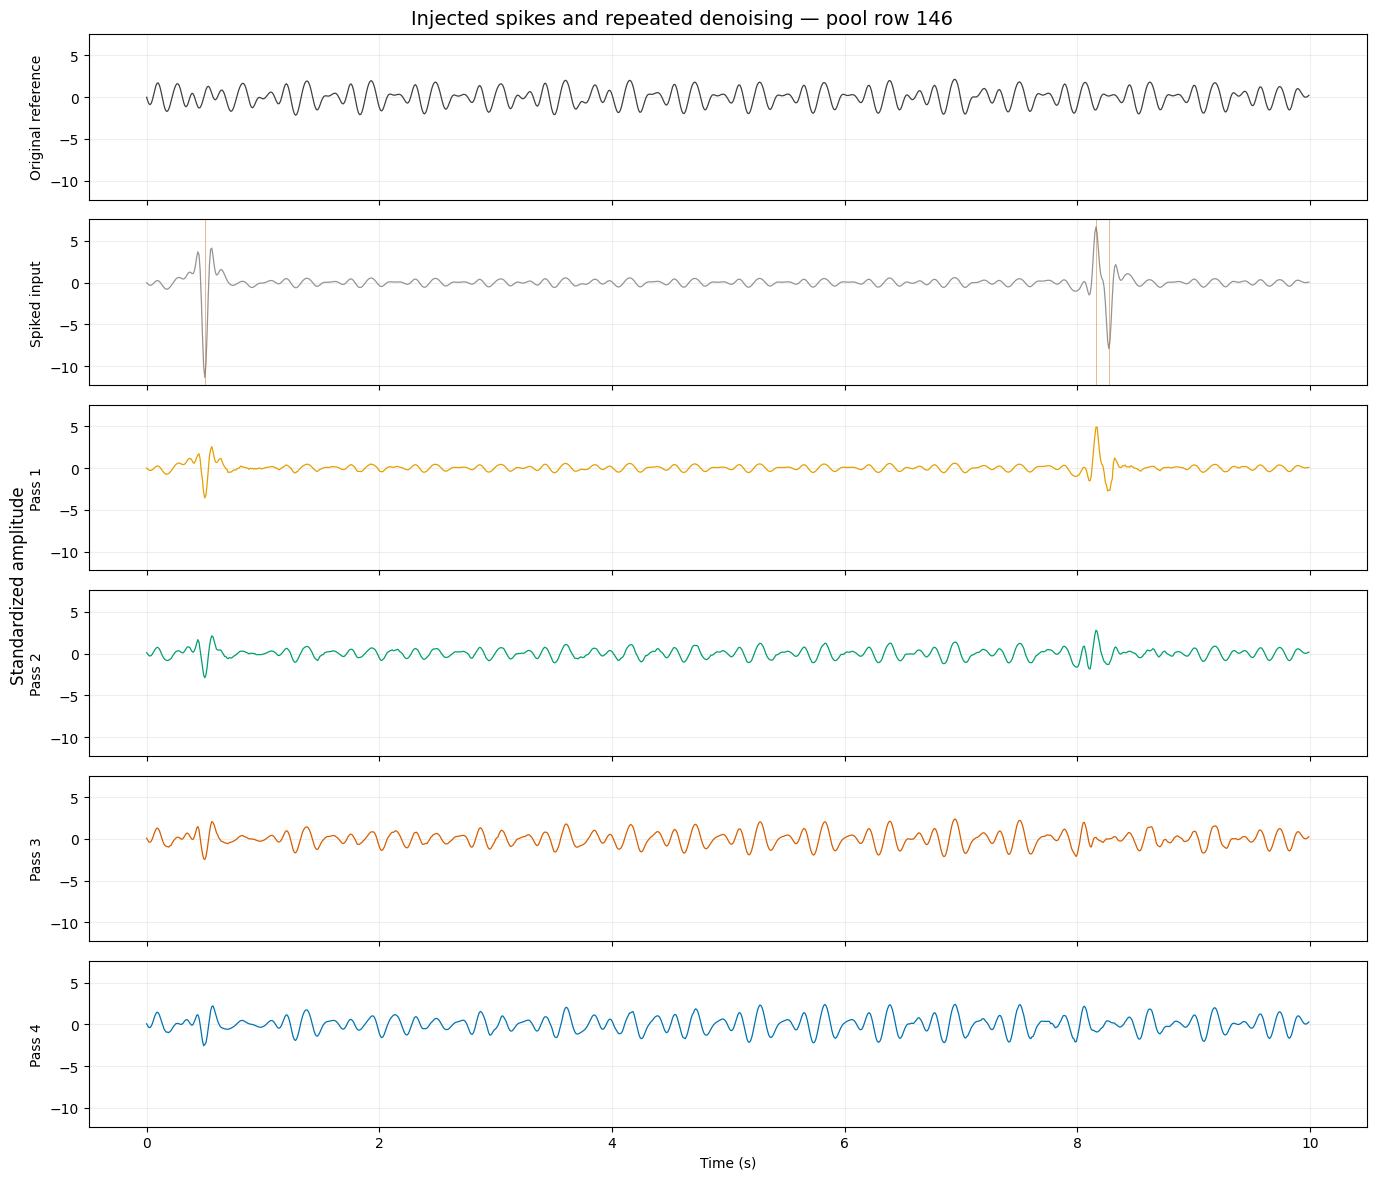

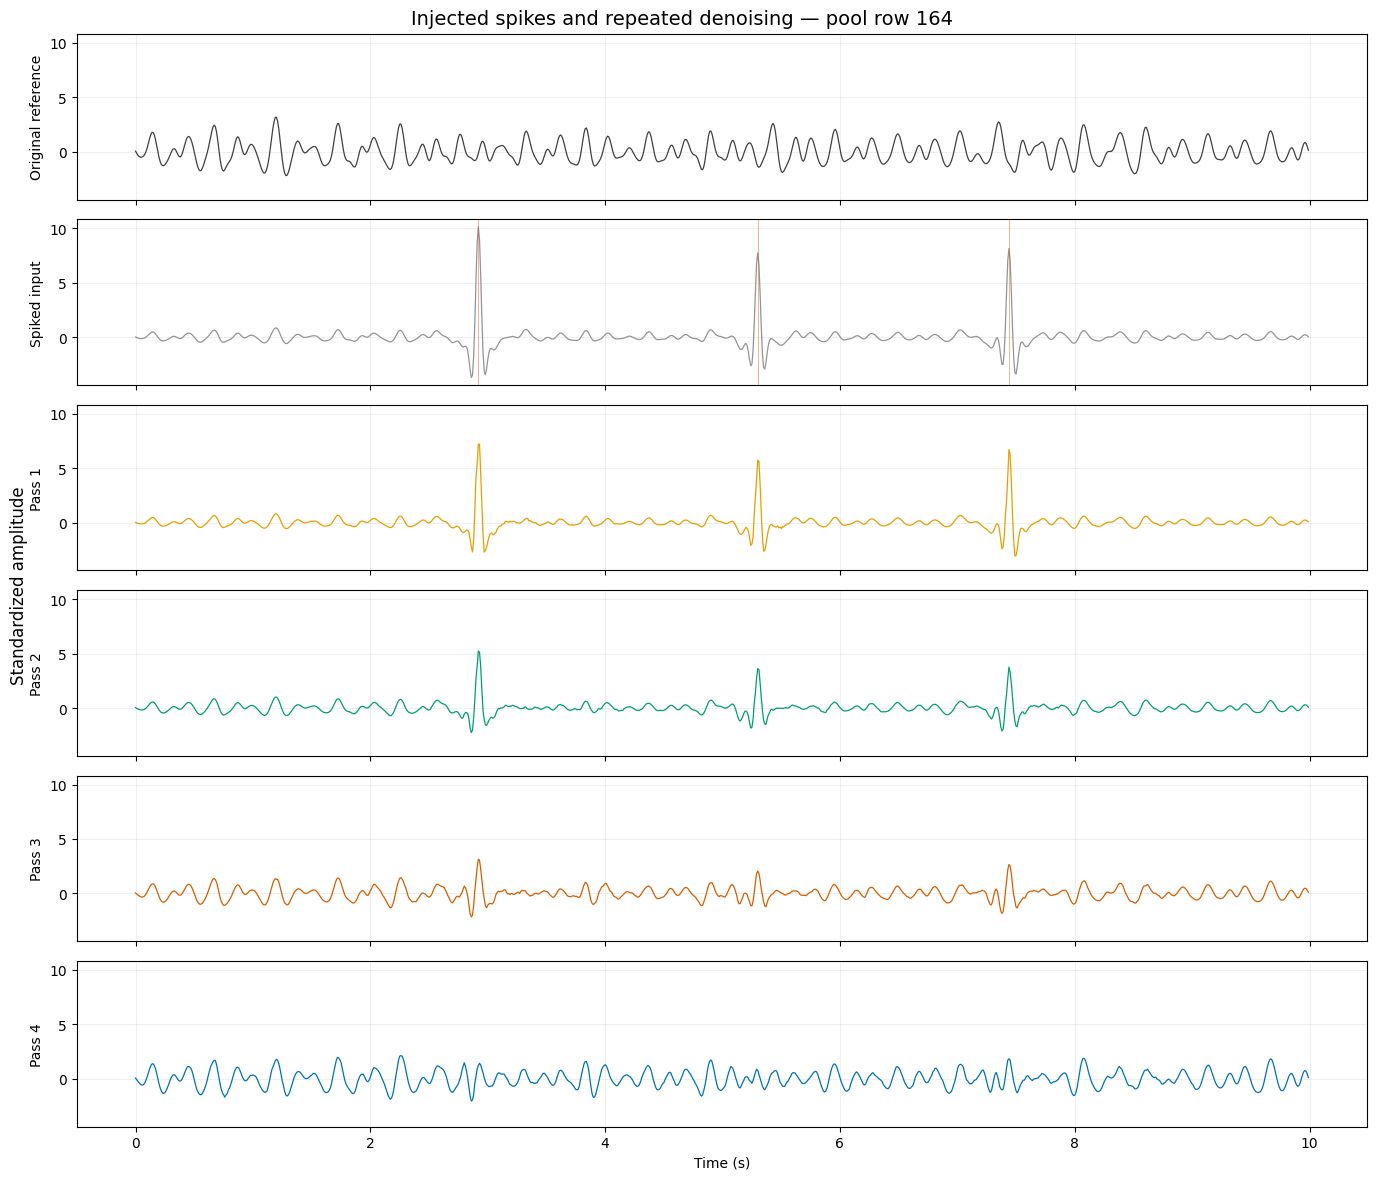

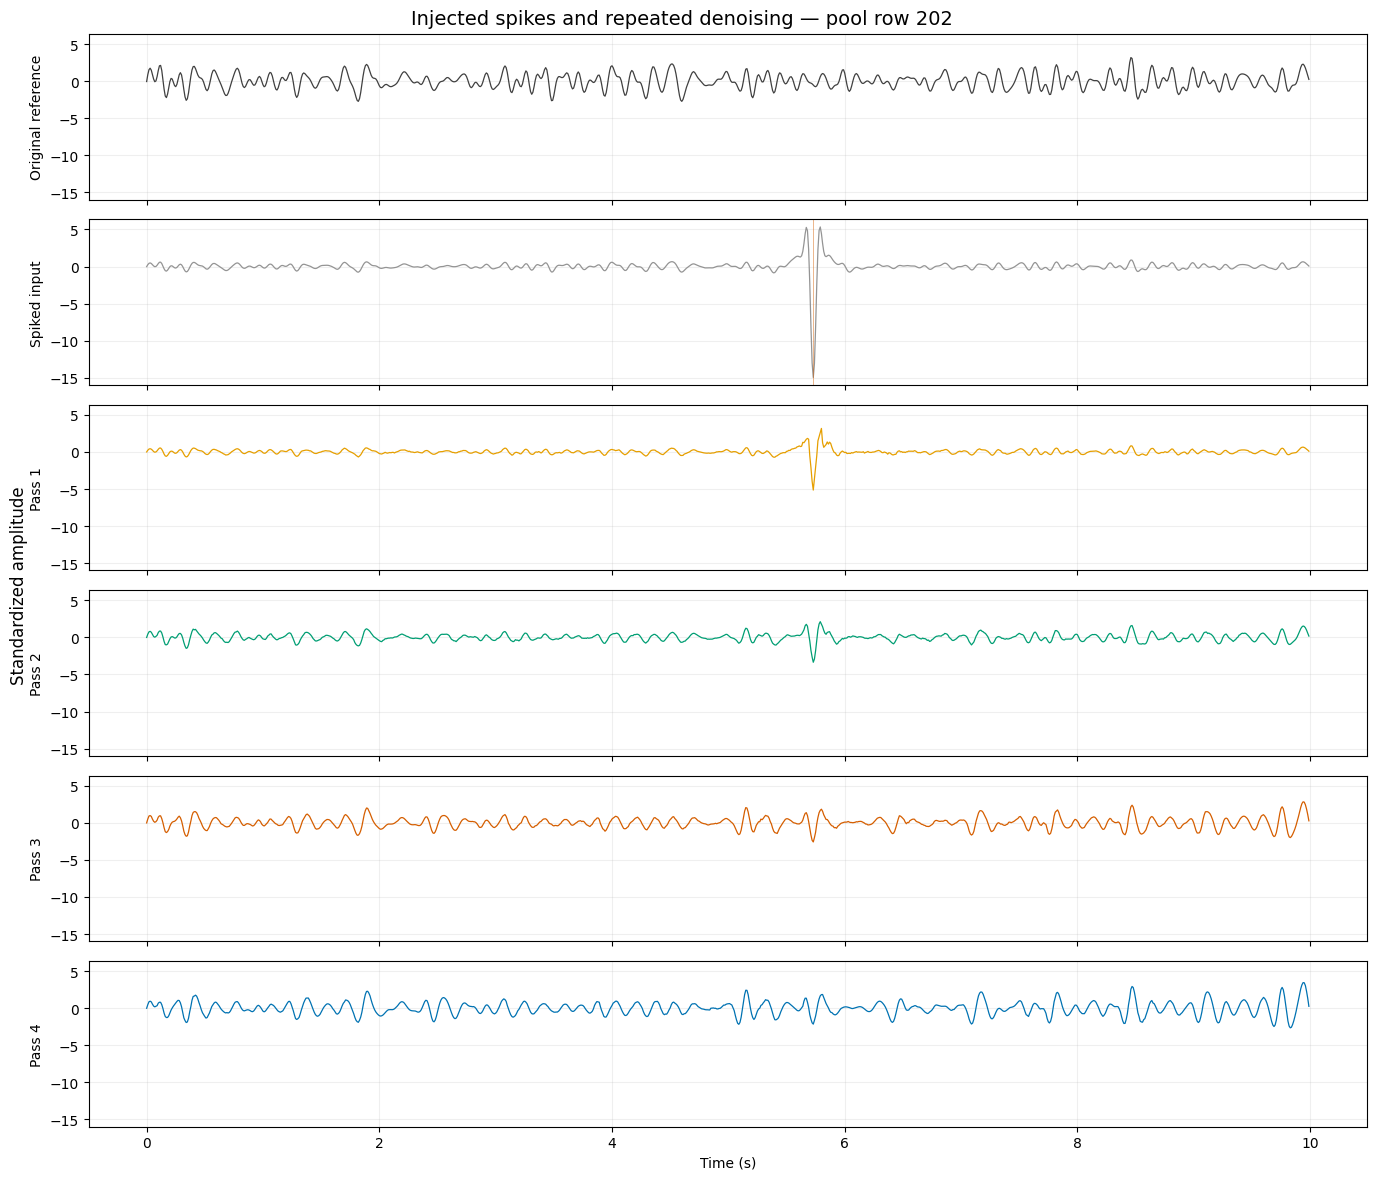

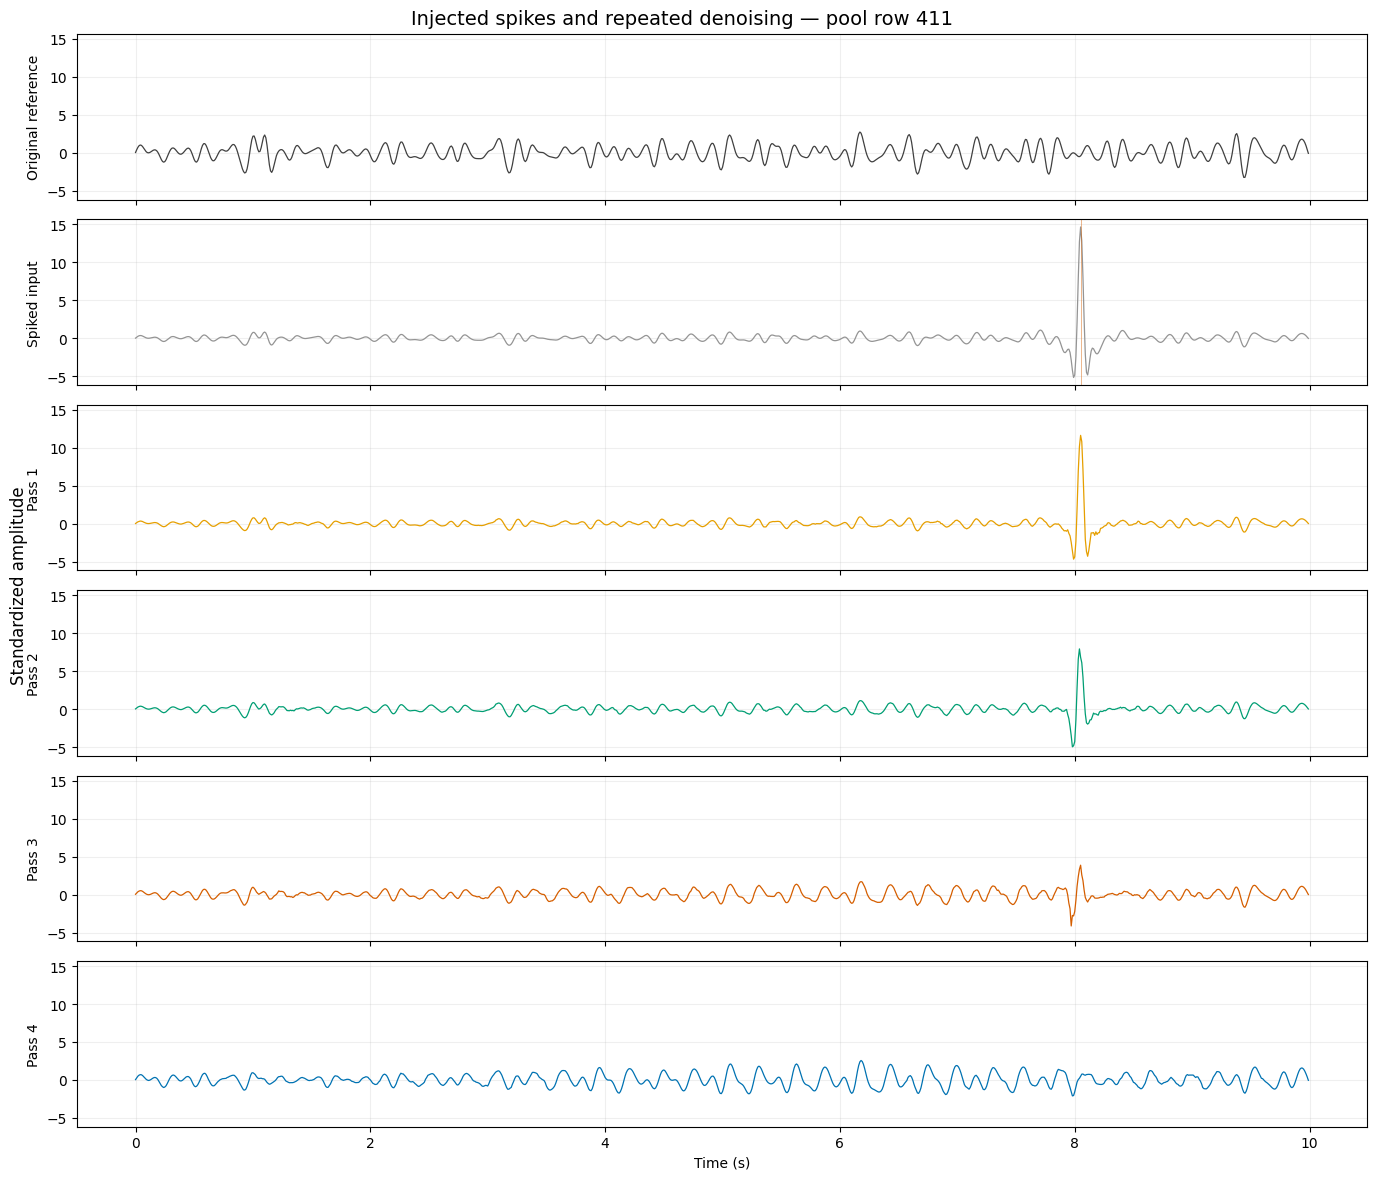

In [12]:
def add_impulse_spikes(signal, rng, count=None, amplitude_range=(100.0, 200.0)):
    if count is None:
        count = int(rng.integers(1, 4))
    spiked = np.asarray(signal, dtype=np.float64).copy()
    positions = np.sort(
        rng.choice(np.arange(50, WINDOW_SAMPLES - 50), size=count, replace=False)
    )
    scale = max(float(np.std(spiked)), 1e-8)
    amplitudes = (
        rng.choice([-1.0, 1.0], size=count)
        * rng.uniform(*amplitude_range, size=count)
        * scale
    )
    spiked[positions] += amplitudes
    return spiked, positions, amplitudes

def run_injected_spikes(model, signals, indices, passes=4, seed=20261108):
    results = []
    for pool_index in indices:
        original = np.asarray(signals[int(pool_index)], dtype=np.float64)
        rng = np.random.default_rng(np.random.SeedSequence([seed, int(pool_index)]))
        spiked, positions, amplitudes = add_impulse_spikes(original, rng)
        current = spiked
        traces = [model.preprocess(spiked)]
        for _ in range(passes):
            current = model.predict(current)
            traces.append(current)
        results.append(
            {
                "pool_index": int(pool_index),
                "original_reference": model.preprocess(original),
                "spike_positions": positions,
                "spike_amplitudes": amplitudes,
                "traces": traces,
            }
        )
    return results

def plot_injected_spikes(results):
    time = np.arange(WINDOW_SAMPLES) / FS
    colors = ["0.25", "0.58", "#E69F00", "#009E73", "#D55E00", "#0072B2"]
    figures = []
    for result in results:
        traces = [result["original_reference"], *result["traces"]]
        labels = ["Original reference", "Spiked input", "Pass 1", "Pass 2", "Pass 3", "Pass 4"]
        fig, axes = plt.subplots(
            len(traces), 1, figsize=(14, 2.0 * len(traces)),
            sharex=True, sharey=True,
        )
        axes = np.atleast_1d(axes)
        for row_index, (trace, label, color) in enumerate(zip(traces, labels, colors)):
            axes[row_index].plot(
                time, trace, color=color, linewidth=0.9, label=label,
            )
            axes[row_index].set_ylabel(label)
            axes[row_index].grid(alpha=0.2)
        for position in result["spike_positions"]:
            axes[1].axvline(
                time[position], color="#D55E00", linewidth=0.7,
                alpha=0.45,
            )
        axes[-1].set_xlabel("Time (s)")
        fig.suptitle(
            f"Injected spikes and repeated denoising — pool row {result['pool_index']}",
            fontsize=14,
        )
        fig.supylabel("Standardized amplitude")
        fig.tight_layout()
        figures.append(fig)
    return figures

spike_results = run_injected_spikes(
    model, signals, display_indices[:4], passes=4,
)
print("Rows used for spike injection:", [row["pool_index"] for row in spike_results])
for row in spike_results:
    print(
        f"row {row['pool_index']:>3}: "
        f"spike positions={row['spike_positions'].tolist()}"
    )
spike_figures = plot_injected_spikes(spike_results)
plt.show()
